# Güneş Santrali Verisiyle Sayısal İntegrasyon ve Türev

**Veri:** Kaggle – *Solar Power Generation Data* (Ani Kannal), `Plant_1_Generation_Data.csv`
Hindistan'da bir güneş santralinin 22 inverterinden, 15 Mayıs – 17 Haziran 2020 arasında 15 dakikada bir alınmış ölçümler.

**Soru:** İnverterin 15 dakikada bir verdiği anlık güç değerlerinden (`AC_POWER`, kW) günlük enerjiyi (kWh)
sayısal integrasyonla ne kadar doğru hesaplayabiliriz? İnverterin kendi sayacı (`TOTAL_YIELD`) bize gerçek bir referans veriyor.

$$E = \int_{\text{gün}} P(t)\,dt \quad [\text{kW} \times \text{saat} = \text{kWh}]$$

**Plan**
1. Veriyi yükle, sorunlarını bul ve temizle
2. Trapez, Simpson ve Romberg'i sıfırdan yaz; bilinen fonksiyonlarda test et
3. Gerçek veride referansla karşılaştır
4. Seyreltme deneyi: adım boyu $h$ büyüdükçe hata nasıl değişiyor?
5. Sayısal türev: gürültü türevde nasıl büyüyor, en iyi $h$ nedir?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import integrate, special, optimize

# Grafik ayarları
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": "#0b0b0b",
    "font.size": 9.5, "legend.frameon": False, "lines.linewidth": 2,
})
MAVI, TURUNCU, YESIL, GRI = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
pd.set_option("display.precision", 4)

## 1. Veriyi yükleme ve temizleme

In [2]:
df = pd.read_csv("Plant_1_Generation_Data.csv")
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], format="%d-%m-%Y %H:%M")
df["tarih"] = df["DATE_TIME"].dt.date
df["saat"] = df["DATE_TIME"].dt.hour + df["DATE_TIME"].dt.minute / 60
df = df.sort_values(["SOURCE_KEY", "DATE_TIME"]).reset_index(drop=True)

print("Satır sayısı      :", len(df))
print("İnverter sayısı   :", df["SOURCE_KEY"].nunique())
print("Tarih aralığı     :", df["DATE_TIME"].min(), "→", df["DATE_TIME"].max())
beklenen = len(pd.date_range(df["DATE_TIME"].min(), df["DATE_TIME"].max(), freq="15min"))
print("Zaman damgası     :", df["DATE_TIME"].nunique(), "/", beklenen, "beklenen")
df.head()

Satır sayısı      : 68778
İnverter sayısı   : 22
Tarih aralığı     : 2020-05-15 00:00:00 → 2020-06-17 23:45:00
Zaman damgası     : 3158 / 3264 beklenen


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,tarih,saat
0,2020-05-15 00:00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,2020-05-15,0.00
1,2020-05-15 00:15:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,2020-05-15,0.25
2,2020-05-15 00:30:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,2020-05-15,0.50
3,2020-05-15 00:45:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,2020-05-15,0.75
4,2020-05-15 01:00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,2020-05-15,1.00


### Veride fark ettiğimiz sorunlar

1. **Eksik ölçümler:** 3264 zaman damgasının 106'sı tamamen yok; bazı inverterlerde ayrıca tek tük boşluklar var.
2. **DC_POWER birimi tutarsız:** DC/AC oranı ≈ 10. Bir inverterin verimi %1000 olamaz, yani DC sütunu büyük ihtimalle 10 kat ölçeklenmiş. Biz yalnızca `AC_POWER` kullanacağız.
3. **DAILY_YIELD her zaman gece yarısı sıfırlanmıyor:** Bazı günler önceki günün değeriyle başlıyor, bazıları gün bitmeden 0'a düşüyor. Bu yüzden referans olarak sürekli artan `TOTAL_YIELD` sayacının farkını kullanacağız.

In [3]:
oran = (df["DC_POWER"] / df["AC_POWER"])[df["AC_POWER"] > 0]
print(f"DC/AC oranı: medyan {oran.median():.2f}")

gece_yarisi = df[df["saat"] == 0]
print("00:00'da DAILY_YIELD > 0 olan inverter-gün sayısı:", (gece_yarisi["DAILY_YIELD"] > 0).sum(), "/", len(gece_yarisi))

print("05:00'ten önce en büyük AC_POWER :", df.loc[df["saat"] < 5, "AC_POWER"].max())
print("19:00'dan sonra en büyük AC_POWER:", df.loc[df["saat"] >= 19, "AC_POWER"].max())
print("Üretimin olduğu saatler          :", df.loc[df["AC_POWER"] > 0, "saat"].min(), "–", df.loc[df["AC_POWER"] > 0, "saat"].max())

DC/AC oranı: medyan 10.22
00:00'da DAILY_YIELD > 0 olan inverter-gün sayısı: 161 / 681
05:00'ten önce en büyük AC_POWER : 0.0
19:00'dan sonra en büyük AC_POWER: 0.0
Üretimin olduğu saatler          : 6.0 – 18.5


### İntegrasyon penceresi: 04:00 – 20:00

Gece güç tam olarak 0, üretim 06:00 ile 18:30 arasında. Bu yüzden integrali **04:00 – 20:00** aralığında alacağız:

* 16 saat ÷ 15 dk = **64 aralık = 2⁶**, yani **65 nokta**. Bu, Romberg için ideal: $h$'yi 6 kez ikiye katlayabiliriz (15 → 30 → 60 → … → 960 dk).
* Pencerenin iki ucunda $P = 0$, ve fonksiyon uçlara yakın bir süre boyunca sıfır kalıyor (bunun neden önemli olduğunu 2. bölümde göreceğiz).

Bu pencerede 65 noktanın **hepsi** bulunan inverter-günleri kullanıyoruz. Referans enerji:

$$E_{\text{ref}} = \mathrm{TOTAL\_YIELD}(20{:}00) - \mathrm{TOTAL\_YIELD}(04{:}00)$$

In [4]:
pencere = df[(df["saat"] >= 4) & (df["saat"] <= 20)]
gunler = {}   # (inverter, tarih) -> AC_POWER dizisi (65 nokta)
ref = {}      # (inverter, tarih) -> referans enerji (kWh)
for (inv, tarih), g in pencere.groupby(["SOURCE_KEY", "tarih"]):
    if len(g) == 65:
        gunler[(inv, tarih)] = g["AC_POWER"].to_numpy()
        ref[(inv, tarih)] = g["TOTAL_YIELD"].iloc[-1] - g["TOTAL_YIELD"].iloc[0]

print("Toplam inverter-gün      :", pencere.groupby(["SOURCE_KEY", "tarih"]).ngroups)
print("Tam (65 nokta) olanlar   :", len(gunler))
t15 = np.linspace(4, 20, 65)   # saat cinsinden zaman ızgarası, h = 0.25 saat

Toplam inverter-gün      : 748
Tam (65 nokta) olanlar   : 487


### AC_POWER anlık değer mi, 15 dakikalık ortalama mı?

Bu soru önemli: Değerler ortalama olsaydı doğru yöntem dikdörtgen kuralı olurdu, anlık örnek olsaydı trapez.
`DAILY_YIELD` içindeki 15 dakikalık artışları ($\Delta Y_i$) üç tahminle karşılaştıralım:

In [5]:
x = df.copy()
grp = x.groupby(["SOURCE_KEY", "tarih"])
x["dY"] = grp["DAILY_YIELD"].diff()
x["dt"] = grp["DATE_TIME"].diff().dt.total_seconds() / 3600
x["P_onceki"] = grp["AC_POWER"].shift()
m = (x["dt"] == 0.25) & (x["dY"] >= 0) & ((x["AC_POWER"] > 0) | (x["P_onceki"] > 0))
y = x[m]

tahminler = {
    "Sol dikdörtgen  h·P(i-1)": 0.25 * y["P_onceki"],
    "Sağ dikdörtgen  h·P(i)":   0.25 * y["AC_POWER"],
    "Trapez  h·(P(i-1)+P(i))/2": 0.25 * (y["P_onceki"] + y["AC_POWER"]) / 2,
}
for ad, tahmin in tahminler.items():
    hata = y["dY"] - tahmin
    print(f"{ad:28s}  ortalama mutlak hata = {hata.abs().mean():6.2f} kWh")
print(f"\n({len(y)} adet 15 dakikalık artış; ortalama artış {y['dY'].mean():.0f} kWh)")

Sol dikdörtgen  h·P(i-1)      ortalama mutlak hata =  15.66 kWh
Sağ dikdörtgen  h·P(i)        ortalama mutlak hata =  16.10 kWh
Trapez  h·(P(i-1)+P(i))/2     ortalama mutlak hata =   7.19 kWh

(37306 adet 15 dakikalık artış; ortalama artış 141 kWh)


Trapez açık ara en iyisi. Demek ki `AC_POWER` **anlık örnek**, inverter ise kendi içinde sürekli integral alıyor.
Bu sayede kuadratür teorisini bu veriye doğrudan uygulayabiliriz.

Şimdi düzgün ve pürüzlü bir günü görelim. Günün "pürüzlülüğünü" ikinci farkların toplamıyla ölçüyoruz:
$R = \sum_i |P_{i+1} - 2P_i + P_{i-1}| \,/\, \overline{P}$ (ortalama güce bölüyoruz).
Pürüzsüz bir çan eğrisinde $R$ küçük, bulut geçişlerinde büyük olur.

Örnek inverter : 1IF53ai7Xc0U56Y
En düzgün gün  : 2020-05-28 (R = 10.1)
En pürüzlü gün : 2020-06-06 (R = 35.4)


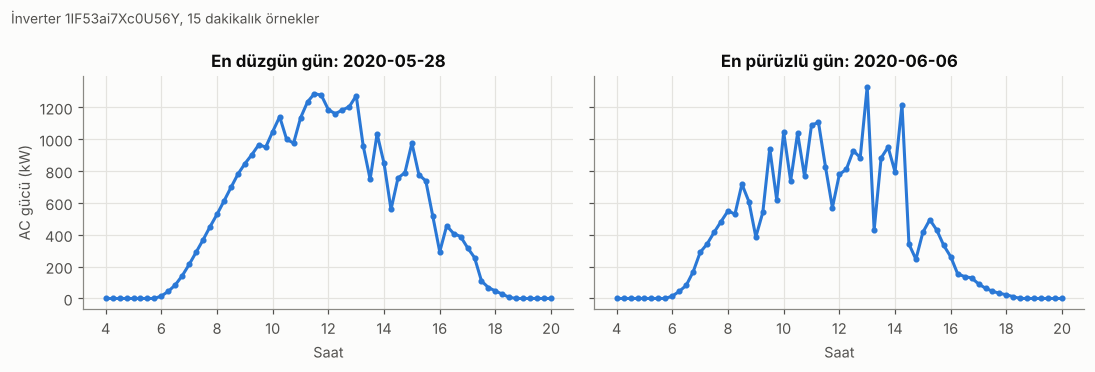

In [6]:
puruz = {k: np.abs(np.diff(p, 2)).sum() / p.mean() for k, p in gunler.items()}
puruz_s = pd.Series(puruz)
ornek_inv, duz_gun = puruz_s.idxmin()                    # tüm veri setindeki en düzgün inverter-gün
puruzlu_gun = puruz_s.xs(ornek_inv, level=0).idxmax()    # aynı inverterin en pürüzlü günü
print("Örnek inverter :", ornek_inv)
print("En düzgün gün  :", duz_gun, f"(R = {puruz[(ornek_inv, duz_gun)]:.1f})")
print("En pürüzlü gün :", puruzlu_gun, f"(R = {puruz[(ornek_inv, puruzlu_gun)]:.1f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, gun, baslik in [(axes[0], duz_gun, "En düzgün gün"), (axes[1], puruzlu_gun, "En pürüzlü gün")]:
    p = gunler[(ornek_inv, gun)]
    ax.plot(t15, p, color=MAVI)
    ax.plot(t15, p, "o", color=MAVI, ms=3)
    ax.set_title(f"{baslik}: {gun}")
    ax.set_xlabel("Saat")
    ax.set_xticks(range(4, 21, 2))
axes[0].set_ylabel("AC gücü (kW)")
fig.suptitle(f"İnverter {ornek_inv}, 15 dakikalık örnekler", x=0.01, ha="left", color="#52514e", fontsize=9)
plt.tight_layout()
plt.show()

Dikkat: **Bu dönemde santralde tamamen açık bir gün yok.** En düzgün günde bile öğleden sonra bulutlar geçiyor (Mayıs–Haziran, muson öncesi Hindistan).
Aşağıda "düzgün günler" derken pürüzlülüğü en düşük %25'lik dilimi, "pürüzlü günler" derken en yüksek %25'lik dilimi kastediyoruz.

## 2. Yöntemler: Trapez, Simpson, Romberg

$n$ eşit aralık, $h = (b-a)/n$, $f_i = f(a + ih)$ için:

* **Bileşik trapez:** $T(h) = h\left[\tfrac12 f_0 + f_1 + \dots + f_{n-1} + \tfrac12 f_n\right]$, hata $O(h^2)$
* **Bileşik Simpson** ($n$ çift): $S(h) = \tfrac{h}{3}\left[f_0 + 4f_1 + 2f_2 + 4f_3 + \dots + 4f_{n-1} + f_n\right]$, hata $O(h^4)$
* **Romberg:** $R_{k,0} = T(h_k)$, $h_k = (b-a)/2^k$, ve Richardson ekstrapolasyonu
  $$R_{k,j} = R_{k,j-1} + \frac{R_{k,j-1} - R_{k-1,j-1}}{4^j - 1}$$
  Not: $R_{k,1}$ tam olarak Simpson'dır: $S(h) = \dfrac{4T(h) - T(2h)}{3}$.

In [7]:
def trapez(f, h):
    """Bileşik trapez kuralı. f: eşit aralıklı örnekler, h: adım boyu."""
    f = np.asarray(f, dtype=float)
    return h * (f.sum() - 0.5 * (f[0] + f[-1]))


def simpson(f, h):
    """Bileşik Simpson 1/3 kuralı. Aralık sayısı (len(f)-1) çift olmalı."""
    f = np.asarray(f, dtype=float)
    n = len(f) - 1
    if n % 2:
        raise ValueError("Simpson için aralık sayısı çift olmalı")
    return h / 3 * (f[0] + f[-1] + 4 * f[1:-1:2].sum() + 2 * f[2:-1:2].sum())


def romberg(f, h):
    """Örneklerden Romberg tablosu. len(f)-1 = 2^k olmalı. (en iyi tahmin, tablo) döndürür."""
    f = np.asarray(f, dtype=float)
    n = len(f) - 1
    k = int(round(np.log2(n)))
    if 2**k != n:
        raise ValueError("Aralık sayısı 2'nin kuvveti olmalı")
    R = np.full((k + 1, k + 1), np.nan)
    for i in range(k + 1):              # i = 0: en kaba ızgara (tek aralık)
        adim = 2 ** (k - i)
        R[i, 0] = trapez(f[::adim], h * adim)
    for i in range(1, k + 1):
        for j in range(1, i + 1):
            R[i, j] = R[i, j - 1] + (R[i, j - 1] - R[i - 1, j - 1]) / (4**j - 1)
    return R[k, k], R

### Doğrulama 1: SciPy ile aynı sonucu veriyor mu?

In [8]:
p = gunler[(ornek_inv, duz_gun)]
print(f"trapez : bizim {trapez(p, 0.25):.6f}   scipy {integrate.trapezoid(p, dx=0.25):.6f}")
print(f"simpson: bizim {simpson(p, 0.25):.6f}   scipy {integrate.simpson(p, dx=0.25):.6f}")
print(f"romberg: bizim {romberg(p, 0.25)[0]:.6f}   scipy {integrate.romb(p, dx=0.25):.6f}")

trapez : bizim 8524.379375   scipy 8524.379375
simpson: bizim 8517.591250   scipy 8517.591250
romberg: bizim 8521.512466   scipy 8521.512466


### Doğrulama 2: Teorik yakınsama mertebeleri

İki test fonksiyonu kullanıyoruz:
* $f(x) = e^x$, $[0,1]$: "sıradan" pürüzsüz fonksiyon. Beklenti: trapez $O(h^2)$, Simpson $O(h^4)$, Romberg çok daha hızlı.
* $f(x) = e^{\cos 2\pi x}$, $[0,1]$: **periyodik** fonksiyon. Tam değeri $I_0(1)$ (modifiye Bessel fonksiyonu).

Log-log grafikte eğim = yakınsama mertebesi.

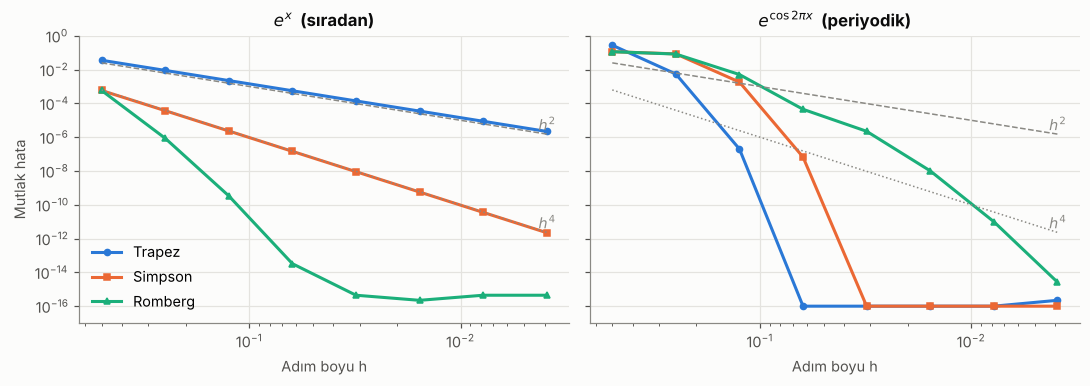

In [9]:
testler = [
    (r"$e^x$  (sıradan)", np.exp, np.e - 1),
    (r"$e^{\cos 2\pi x}$  (periyodik)", lambda x: np.exp(np.cos(2 * np.pi * x)), special.i0(1.0)),
]
n_list = 2 ** np.arange(1, 9)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (ad, f, tam) in zip(axes, testler):
    hT, hS, hR = [], [], []
    for n in n_list:
        xs = np.linspace(0, 1, n + 1)
        h = 1 / n
        hT.append(abs(trapez(f(xs), h) - tam))
        hS.append(abs(simpson(f(xs), h) - tam))
        hR.append(abs(romberg(f(xs), h)[0] - tam))
    hs = 1 / n_list
    eps = 1e-16  # log eksende 0 gösterilemez
    ax.loglog(hs, np.maximum(hT, eps), "o-", color=MAVI, label="Trapez", ms=4)
    ax.loglog(hs, np.maximum(hS, eps), "s-", color=TURUNCU, label="Simpson", ms=4)
    ax.loglog(hs, np.maximum(hR, eps), "^-", color=YESIL, label="Romberg", ms=4)
    ax.loglog(hs, 0.1 * hs**2, "--", color=GRI, lw=1)
    ax.text(hs[-1] * 0.9, 0.1 * hs[-1] ** 2, r"$h^2$", color=GRI, ha="right", va="bottom")
    ax.loglog(hs, 0.01 * hs**4, ":", color=GRI, lw=1)
    ax.text(hs[-1] * 0.9, 0.01 * hs[-1] ** 4, r"$h^4$", color=GRI, ha="right", va="bottom")
    ax.set_title(ad)
    ax.set_xlabel("Adım boyu h")
    ax.invert_xaxis()
    ax.set_ylim(1e-17, 1)
axes[0].set_ylabel("Mutlak hata")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Soldaki grafik** teoriyle birebir uyumlu: trapez $h^2$, Simpson $h^4$ eğimiyle iniyor, Romberg birkaç adımda makine hassasiyetine ulaşıyor.

**Sağdaki grafik** şaşırtıcı: Periyodik fonksiyonda **trapez üstel hızla** yakınsıyor ve Simpson'dan *daha iyi*. Nedeni **Euler–Maclaurin formülü**:

$$T(h) - \int_a^b f\,dx = \frac{h^2}{12}\big[f'(b) - f'(a)\big] - \frac{h^4}{720}\big[f'''(b) - f'''(a)\big] + \dots$$

Periyodik fonksiyonda tüm türevler uçlarda eşit, yani **bütün düzeltme terimleri sıfır**. Simpson $= (4T(h) - T(2h))/3$ ise $h^2$ teriminin var olduğunu varsayıp onu yok etmeye çalışıyor. Ama ortada yok edilecek bir $h^2$ terimi yok, sonuçta $T(2h)$'nin daha büyük hatasını içeri taşımış oluyor.

**Güneş verisiyle bağlantısı:** 04:00–20:00 penceresinin iki ucunda güç **ve tüm türevleri** sıfır. Euler–Maclaurin'deki uç terimleri burada da yok. O zaman güneş verisinde de trapezin Simpson'u yenmesini bekleyebiliriz. Bakalım:

## 3. Gerçek veri: 15 dakikalık örneklerle günlük enerji

In [10]:
satirlar = []
for k, p in gunler.items():
    E = ref[k]
    satirlar.append({
        "inverter": k[0], "tarih": k[1], "E_ref": E, "puruz": puruz[k],
        "Trapez": (trapez(p, 0.25) - E) / E,
        "Simpson": (simpson(p, 0.25) - E) / E,
        "Romberg": (romberg(p, 0.25)[0] - E) / E,
    })
sonuc = pd.DataFrame(satirlar)
q25, q75 = sonuc["puruz"].quantile([0.25, 0.75])
sonuc["gokyuzu"] = np.where(sonuc["puruz"] <= q25, "düzgün", np.where(sonuc["puruz"] >= q75, "pürüzlü", "orta"))

yontemler = ["Trapez", "Simpson", "Romberg"]
tablo = pd.DataFrame({
    "Hepsi": sonuc[yontemler].abs().median(),
    "Düzgün günler (en düşük R %25)": sonuc.loc[sonuc.gokyuzu == "düzgün", yontemler].abs().median(),
    "Pürüzlü günler (en yüksek R %25)": sonuc.loc[sonuc.gokyuzu == "pürüzlü", yontemler].abs().median(),
}) * 100
print(f"Ortalama günlük enerji: {sonuc['E_ref'].mean():.0f} kWh,  inverter-gün sayısı: {len(sonuc)}\n")
print("Medyan |göreli hata| (%), h = 15 dk:")
tablo.round(3)

Ortalama günlük enerji: 6982 kWh,  inverter-gün sayısı: 487

Medyan |göreli hata| (%), h = 15 dk:


,Hepsi,Düzgün günler (en düşük R %25),Pürüzlü günler (en yüksek R %25)
Trapez,0.280,0.158,0.366
Simpson,0.428,0.245,0.752
Romberg,0.499,0.291,0.917


Beklediğimiz gibi: **15 dakikalık veride trapez en iyi yöntem.** Hem Simpson hem Romberg daha kötü; pürüzlü günlerde fark daha da büyük.

Bunun iki nedeni var:
1. **Uç terimleri yok** (Euler–Maclaurin): trapezin $h^2$ hatasının baskın kısmı zaten ortadan kalkmış.
2. **Veri pürüzsüz değil:** Simpson ve Romberg, fonksiyonun yüksek mertebeden türevlerinin sınırlı olduğunu varsayıyor. Bulut geçişleri bu varsayımı bozuyor; Richardson ekstrapolasyonu ise kaba ızgaranın hatasını büyüterek sonuca taşıyor.

Kalan ~%0,3'lük hatanın kaynağı yöntem değil, **örnekleme**: İnverter sürekli ölçüyor, biz ise 15 dakikada bir tek bir değer görüyoruz. İki örnek arasındaki bulut dalgalanmalarını hiçbir kuadratür kuralı göremez.
Pürüzlü günlerde hatanın daha büyük olmasını bekleriz. Bakalım:

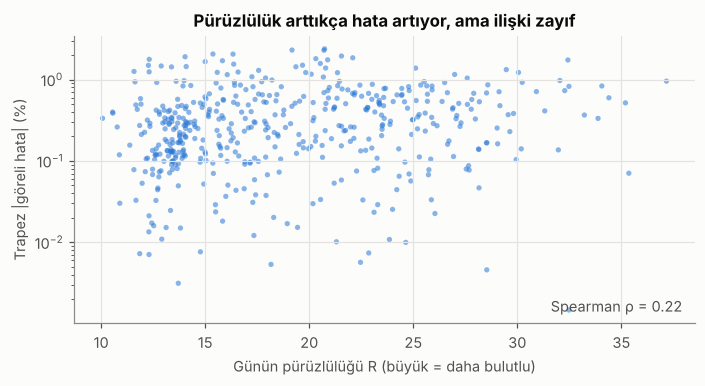

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(sonuc["puruz"], sonuc["Trapez"].abs() * 100, s=12, color=MAVI, alpha=0.55, edgecolors="none")
ax.set_yscale("log")
ax.set_xlabel("Günün pürüzlülüğü R (büyük = daha bulutlu)")
ax.set_ylabel("Trapez |göreli hata| (%)")
ax.set_title("Pürüzlülük arttıkça hata artıyor, ama ilişki zayıf")
r_s = sonuc[["puruz"]].assign(h=sonuc["Trapez"].abs()).corr(method="spearman").iloc[0, 1]
ax.text(0.98, 0.04, f"Spearman ρ = {r_s:.2f}", transform=ax.transAxes, ha="right", color="#52514e")
plt.tight_layout()
plt.show()

Eğilim var (ρ ≈ 0,2), ama saçılma büyük. Sebebi: Hata, bulutların ne kadar sık geçtiğinden çok, **örnekleme anlarına denk gelip gelmediğine** bağlı.
Bir bulut tam bir ölçüm anında gölge yaparsa trapez o 30 dakikayı eksik sayar; iki ölçüm arasında gelip geçerse hiç fark etmez, ama enerji kaybolmuştur.
Bu rastgelelik yüzünden aynı pürüzlülükteki iki gün çok farklı hatalar verebiliyor.

### Bir günün Romberg tablosu

Satırlar yukarıdan aşağı $h$ = 960, 480, 240, 120, 60, 30, 15 dakika (ilk satır tek aralık: iki ucu da 0 olduğu için integral 0).
İlk sütun trapez, ikinci sütun Simpson, sonrakiler daha yüksek mertebeden ekstrapolasyonlar.

In [12]:
for gun, ad in [(duz_gun, "Düzgün gün"), (puruzlu_gun, "Pürüzlü gün")]:
    p = gunler[(ornek_inv, gun)]
    _, R = romberg(p, 0.25)
    E = ref[(ornek_inv, gun)]
    tbl = pd.DataFrame(R, index=[f"h = {15 * 2**(6 - i)} dk" for i in range(7)],
                       columns=[f"R[·,{j}]" for j in range(7)])
    print(f"{ad} ({gun}), referans E = {E:.0f} kWh")
    display(tbl.round(1))

Düzgün gün (2020-05-28), referans E = 8496 kWh


,"R[·,0]","R[·,1]","R[·,2]","R[·,3]","R[·,4]","R[·,5]","R[·,6]"
h = 960 dk,0.0,NaN,NaN,NaN,NaN,NaN,NaN
h = 480 dk,9487.3,12649.7,NaN,NaN,NaN,NaN,NaN
h = 240 dk,8032.9,7548.1,7208.0,NaN,NaN,NaN,NaN
h = 120 dk,7936.2,7903.9,7927.6,7939.0,NaN,NaN,NaN
h = 60 dk,8731.9,8997.2,9070.1,9088.2,9092.7,NaN,NaN
h = 30 dk,8544.7,8482.3,8448.0,8438.2,8435.6,8435.0,NaN
h = 15 dk,8524.4,8517.6,8519.9,8521.1,8521.4,8521.5,8521.5


Pürüzlü gün (2020-06-06), referans E = 6542 kWh


,"R[·,0]","R[·,1]","R[·,2]","R[·,3]","R[·,4]","R[·,5]","R[·,6]"
h = 960 dk,0.0,NaN,NaN,NaN,NaN,NaN,NaN
h = 480 dk,6236.9,8315.9,NaN,NaN,NaN,NaN,NaN
h = 240 dk,6368.8,6412.8,6285.9,NaN,NaN,NaN,NaN
h = 120 dk,6941.0,7131.8,7179.7,7193.9,NaN,NaN,NaN
h = 60 dk,7074.3,7118.8,7117.9,7116.9,7116.6,NaN,NaN
h = 30 dk,6932.5,6885.2,6869.6,6865.7,6864.7,6864.4,NaN
h = 15 dk,6537.4,6405.7,6373.7,6365.9,6363.9,6363.4,6363.3


* **Düzgün günde** Romberg (8521,5) ile 15 dakikalık trapez (8524,4) neredeyse aynı; referanstan ikisi de ~%0,3 sapıyor.
* **Pürüzlü günde** trapez referansa 5 kWh yakın, Romberg ise ~180 kWh (%2,7) sapıyor.

İlk sütuna bakın: $h$ küçüldükçe trapez değerleri düzenli biçimde bir limite yaklaşmıyor, bir aşağı bir yukarı zıplıyor.
Richardson ekstrapolasyonu $T(h) \approx I + c\,h^2$ ilişkisini varsayıyor; burada bu ilişki yok. Ekstrapolasyon da kaba ızgaraların (gün içinde sadece 2–5 nokta!) gelişigüzel hatalarını sonuca taşıyor.

## 4. Seyreltme deneyi: hata adım boyuna nasıl bağlı?

Her günün 15 dakikalık verisini her 2., 4., 8., 16. noktayı alarak seyreltiyoruz: $h$ = 15, 30, 60, 120, 240 dk.
Referans hep inverterin kendi sayacı. Teoriye göre trapez hatası $\propto h^2$, Simpson hatası $\propto h^4$ olmalıydı.

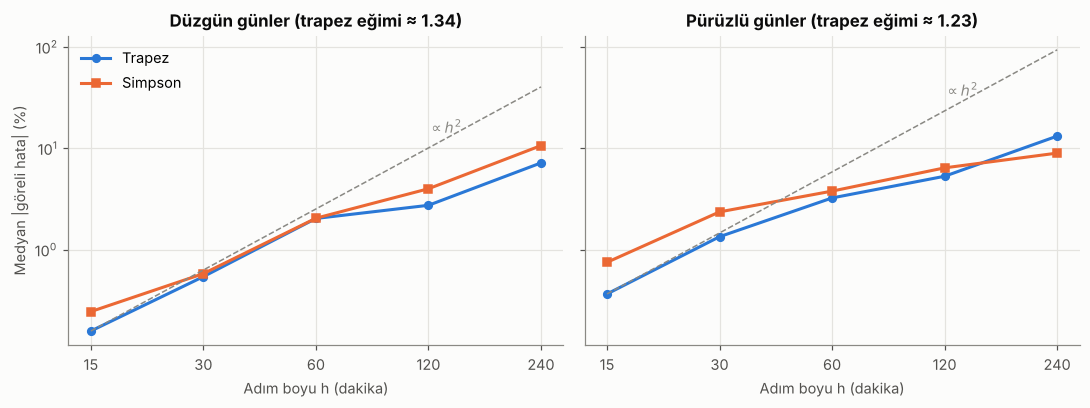

Medyan |göreli hata| (%):


Trapez                Simpson               
gokyuzu düzgün   orta pürüzlü  düzgün   orta pürüzlü
h_dk                                                
15       0.158  0.298   0.366   0.245  0.463   0.752
30       0.543  0.887   1.344   0.581  1.246   2.363
60       2.035  2.738   3.243   2.046  2.831   3.788
120      2.744  6.405   5.306   3.998  6.713   6.423
240      7.188  9.478  13.209  10.652  9.147   8.979

In [13]:
adimlar = [1, 2, 4, 8, 16]
h_dk = np.array([15 * s for s in adimlar])
kayit = []
for k, p in gunler.items():
    E = ref[k]
    for s in adimlar:
        kayit.append({"k": k, "h_dk": 15 * s, "gokyuzu": "",
                      "Trapez": abs(trapez(p[::s], 0.25 * s) - E) / E,
                      "Simpson": abs(simpson(p[::s], 0.25 * s) - E) / E})
seyrek = pd.DataFrame(kayit)
seyrek["gokyuzu"] = seyrek["k"].map(dict(zip(zip(sonuc.inverter, sonuc.tarih), sonuc.gokyuzu)))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, gk in zip(axes, ["düzgün", "pürüzlü"]):
    med = seyrek[seyrek.gokyuzu == gk].groupby("h_dk")[["Trapez", "Simpson"]].median() * 100
    ax.loglog(med.index, med["Trapez"], "o-", color=MAVI, label="Trapez", ms=5)
    ax.loglog(med.index, med["Simpson"], "s-", color=TURUNCU, label="Simpson", ms=5)
    ref_c = med["Trapez"].iloc[0] * (h_dk / 15) ** 2
    ax.loglog(h_dk, ref_c, "--", color=GRI, lw=1)
    ax.text(h_dk[-2], ref_c[-2] * 1.4, r"$\propto h^2$", color=GRI)
    egim = np.polyfit(np.log(med.index), np.log(med["Trapez"]), 1)[0]
    ax.set_title(f"{gk.capitalize()} günler (trapez eğimi ≈ {egim:.2f})")
    ax.set_xlabel("Adım boyu h (dakika)")
    ax.minorticks_off()
    ax.set_xticks(h_dk)
    ax.set_xticklabels(h_dk)
axes[0].set_ylabel("Medyan |göreli hata| (%)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

print("Medyan |göreli hata| (%):")
seyrek.groupby(["gokyuzu", "h_dk"])[["Trapez", "Simpson"]].median().unstack(0).mul(100).round(3)

**Yorum**
* Düzgün günlerde 15 → 30 → 60 dk arasında hata $h^2$ çizgisini neredeyse birebir takip ediyor; sonrasında kopuyor. Uydurulan toplam eğim ≈ 1,2–1,3, teorideki 2'nin oldukça altında.
  Çok kaba ızgarada (120–240 dk, gün içinde 5–9 nokta) hata artık "asimptotik bölgede" değil; teorem $h \to 0$ limitinden söz ediyor.
* **$h \le 120$ dk'da Simpson trapezi hiç geçmiyor.** $O(h^4)$ vaadi $f^{(4)}$'ün sınırlı ve küçük olmasına dayanıyor; bulut geçişlerinde bu varsayım çöküyor. (240 dk'da pürüzlü günlerde Simpson daha iyi görünüyor, ama 5 noktalık bir ızgarada bu artık şans meselesi.)
* Pratik sonuç: Saatlik veriyle (h = 60 dk) günlük enerji %2–3 hatayla bulunuyor; 30 dakikada hata %0,5–1,3'e iniyor.

## 5. Sayısal türev ve gürültü

Güç değişim hızı $P'(t)$ (kW/saat) bulut geçişlerini ve rampaları anlamak için önemli. Sonlu farklar:

* İleri fark: $D_+ f = \dfrac{f(t+h) - f(t)}{h}$, kesme hatası $\dfrac{h}{2}f''$, $O(h)$
* Merkezi fark: $D_0 f = \dfrac{f(t+h) - f(t-h)}{2h}$, kesme hatası $\dfrac{h^2}{6}f'''$, $O(h^2)$

Önce gerçek veride merkezi farkı görelim:

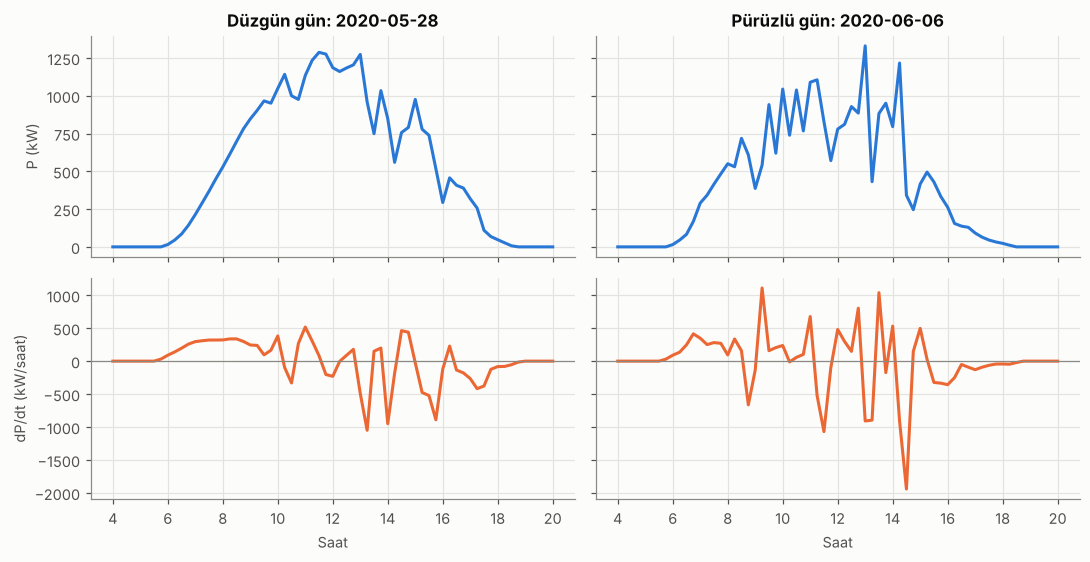

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5.2), sharex=True, sharey="row")
for j, (gun, ad) in enumerate([(duz_gun, "Düzgün gün"), (puruzlu_gun, "Pürüzlü gün")]):
    p = gunler[(ornek_inv, gun)]
    dp = np.gradient(p, 0.25)   # iç noktalarda merkezi fark
    axes[0, j].plot(t15, p, color=MAVI)
    axes[0, j].set_title(f"{ad}: {gun}")
    axes[1, j].plot(t15, dp, color=TURUNCU)
    axes[1, j].axhline(0, color=GRI, lw=0.8)
    axes[1, j].set_xlabel("Saat")
    axes[1, j].set_xticks(range(4, 21, 2))
axes[0, 0].set_ylabel("P (kW)")
axes[1, 0].set_ylabel("dP/dt (kW/saat)")
plt.tight_layout()
plt.show()

Sabah rampasında (06:00–10:00) türev düzgün ve yorumlanabilir: güç saatte ~300 kW artıyor. Öğleden sonra ise her iki günde de türev bulut kaynaklı sıçramalardan ibaret; güç eğrisi hâlâ "okunabilir" ama türev neredeyse tamamen gürültü.
**Türev almak gürültüyü büyütür:** $f$'deki $\varepsilon$ boyutundaki bir hata, $D_0 f$'de $\varepsilon/h$ boyutunda bir hataya dönüşür.

### Kontrollü deney: en iyi adım boyu

Gerçek veride 15 dakikadan küçük $h$ deneyemiyoruz ve "gerçek" türevi bilmiyoruz. O yüzden:
1. En düzgün günün **sabah rampasına** (bulutların gelmediği 06:00–11:30 arası) pürüzsüz bir model uyduralım:
   $P(t) = A\,\sin^{\,k}\!\big(\pi\,\frac{t - t_1}{t_2 - t_1}\big)$, $t_1 < t < t_2$ (gün doğumu $t_1$, gün batımı $t_2$)
2. Bulutlar gelmeden önceki rampada (06:30–10:00) modelden sapmaların standart sapmasını **gürültü seviyesi** $\sigma$ olarak alalım
3. Modeli 1 dakikalık ızgarada üretip $\sigma$ gürültü ekleyelim ve 08:30–11:00 arasında türevi farklı $h$'lerle hesaplayalım. Gerçek türevi bildiğimiz için hatayı ölçebiliriz.
   (Bölgeyi 08:30'dan başlatıyoruz ki $t - h$ en büyük $h$'de bile gün doğumundaki köşeye, $t_1$'e çarpmasın.)

Model: A = 1217 kW, t1 = 6.20 sa, t2 = 17.91 sa, k = 1.06
Gürültü seviyesi σ ≈ 27.8 kW  (tepe gücün %2.3'i)


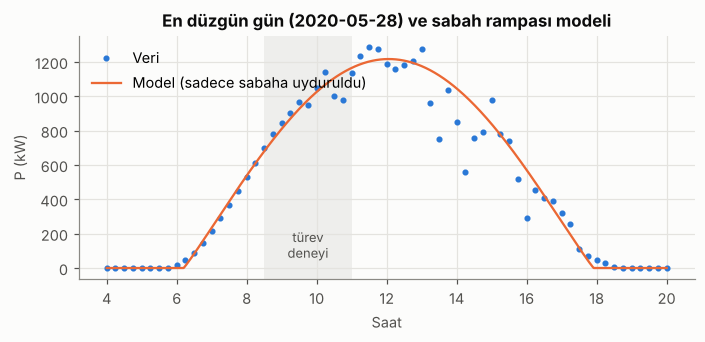

In [15]:
def model(t, A, t1, t2, k):
    u = np.clip((t - t1) / (t2 - t1), 0, 1)
    return A * np.sin(np.pi * u) ** k

p_duz = gunler[(ornek_inv, duz_gun)]
sabah = t15 <= 11.5
param, _ = optimize.curve_fit(model, t15[sabah], p_duz[sabah], p0=[1300, 6, 18.5, 1.5],
                              bounds=([500, 5, 17, 0.5], [2000, 7.5, 20, 4]))
artik = p_duz - model(t15, *param)
rampa = (t15 >= 6.5) & (t15 <= 10.0)      # bulutlar gelmeden önceki rampa
sigma = np.sqrt(np.sum(artik[rampa] ** 2) / (rampa.sum() - 4))   # 4 parametre uydurduk
print("Model: A = {:.0f} kW, t1 = {:.2f} sa, t2 = {:.2f} sa, k = {:.2f}".format(*param))
print(f"Gürültü seviyesi σ ≈ {sigma:.1f} kW  (tepe gücün %{100 * sigma / param[0]:.1f}'i)")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(t15, p_duz, "o", color=MAVI, ms=3, label="Veri")
tt = np.linspace(4, 20, 1000)
ax.plot(tt, model(tt, *param), color=TURUNCU, lw=1.5, label="Model (sadece sabaha uyduruldu)")
ax.axvspan(8.5, 11, color=GRI, alpha=0.12, lw=0)
ax.text(9.75, 60, "türev\ndeneyi", ha="center", color="#52514e", fontsize=8.5)
ax.set_xlabel("Saat"); ax.set_ylabel("P (kW)")
ax.set_title(f"En düzgün gün ({duz_gun}) ve sabah rampası modeli")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Toplam hata iki parçadan oluşur. Merkezi fark için:

$$E(h) \approx \underbrace{\frac{h^2}{6}\,|f'''|}_{\text{kesme}} \;+\; \underbrace{\frac{\sigma}{\sqrt2\,h}}_{\text{gürültü}}$$

$h$ küçülünce kesme hatası azalır ama gürültü terimi patlar. Minimum noktası: $h^* = \left(\dfrac{3\sigma}{\sqrt2\,M}\right)^{1/3}$, burada $M = |f'''|$ (biz karesel ortalamasını kullanıyoruz).

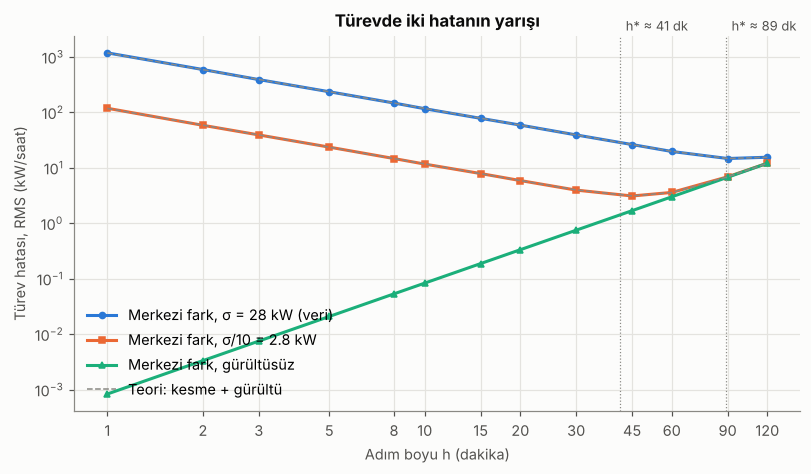

σ   : teorik h* =  89.0 dk | deneyde en iyi h =  90 dk (RMS  14.8 kW/saat) | h = 1 dk'da RMS   1186 kW/saat
σ/10: teorik h* =  41.3 dk | deneyde en iyi h =  45 dk (RMS   3.1 kW/saat) | h = 1 dk'da RMS    119 kW/saat

İleri fark (σ), en iyi h'de RMS: 55 kW/saat  ← merkezi farktan 3.7 kat kötü
Karşılaştırma: bu bölgede tipik |P'| ≈ 194 kW/saat


In [16]:
rng = np.random.default_rng(0)
dk = 1 / 60                                   # 1 dakika (saat cinsinden)
t_ince = np.arange(4, 20 + dk / 2, dk)
f_ince = model(t_ince, *param)

# Gerçek türevler (çok ince ızgarada, gürültüsüz)
t_cok_ince = np.arange(4, 20, 1e-4)
f_cok = model(t_cok_ince, *param)
d1 = np.gradient(f_cok, 1e-4); d2 = np.gradient(d1, 1e-4); d3 = np.gradient(d2, 1e-4)
gercek_turev = lambda t: np.interp(t, t_cok_ince, d1)
bolge = (t_cok_ince >= 8.5) & (t_cok_ince <= 11)      # değerlendirme bölgesi: 08:30–11:00
M3 = np.sqrt(np.mean(d3[bolge] ** 2))

h_dakika = np.array([1, 2, 3, 5, 8, 10, 15, 20, 30, 45, 60, 90, 120])
i0 = np.where((t_ince >= 8.5 - 1e-9) & (t_ince <= 11 + 1e-9))[0]   # türevi hesapladığımız noktalar
gt = gercek_turev(t_ince[i0])

def turev_hatasi(s, tekrar=200):
    """Gürültü seviyesi s için her h'de ileri ve merkezi farkın RMS hatası."""
    ileri, merkez = [], []
    for hd in h_dakika:
        h = hd * dk
        e_i, e_m = [], []
        for _ in range(tekrar):
            g = f_ince + rng.normal(0, s, f_ince.size)
            e_i.append((g[i0 + hd] - g[i0]) / h - gt)
            e_m.append((g[i0 + hd] - g[i0 - hd]) / (2 * h) - gt)
        ileri.append(np.sqrt(np.mean(np.square(e_i))))
        merkez.append(np.sqrt(np.mean(np.square(e_m))))
    return np.array(ileri), np.array(merkez)

h_saat = h_dakika * dk
teori = lambda s: np.sqrt((h_saat**2 / 6 * M3) ** 2 + (s / (np.sqrt(2) * h_saat)) ** 2)
h_opt = lambda s: (3 * s / (np.sqrt(2) * M3)) ** (1 / 3) * 60   # dakika

ileri_1, merkez_1 = turev_hatasi(sigma)
_, merkez_10 = turev_hatasi(sigma / 10)
temiz = np.array([np.sqrt(np.mean(((f_ince[i0 + hd] - f_ince[i0 - hd]) / (2 * hd * dk) - gt) ** 2)) for hd in h_dakika])

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.loglog(h_dakika, merkez_1, "o-", color=MAVI, ms=4, label=f"Merkezi fark, σ = {sigma:.0f} kW (veri)")
ax.loglog(h_dakika, merkez_10, "s-", color=TURUNCU, ms=4, label=f"Merkezi fark, σ/10 = {sigma / 10:.1f} kW")
ax.loglog(h_dakika, temiz, "^-", color=YESIL, ms=4, label="Merkezi fark, gürültüsüz")
ax.loglog(h_dakika, teori(sigma), "--", color=GRI, lw=1, label="Teori: kesme + gürültü")
ax.loglog(h_dakika, teori(sigma / 10), "--", color=GRI, lw=1)
for s in (sigma, sigma / 10):
    ax.axvline(h_opt(s), color=GRI, lw=0.8, ls=":")
    ax.text(h_opt(s) * 1.04, 3e3, f"h* ≈ {h_opt(s):.0f} dk", color="#52514e", fontsize=8.5)
ax.minorticks_off()
ax.set_xticks(h_dakika); ax.set_xticklabels(h_dakika)
ax.set_xlabel("Adım boyu h (dakika)")
ax.set_ylabel("Türev hatası, RMS (kW/saat)")
ax.set_title("Türevde iki hatanın yarışı")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

for ad, m, s in [("σ   ", merkez_1, sigma), ("σ/10", merkez_10, sigma / 10)]:
    i = int(np.argmin(m))
    print(f"{ad}: teorik h* = {h_opt(s):5.1f} dk | deneyde en iyi h = {h_dakika[i]:3d} dk "
          f"(RMS {m[i]:5.1f} kW/saat) | h = 1 dk'da RMS {m[0]:6.0f} kW/saat")
print(f"\nİleri fark (σ), en iyi h'de RMS: {ileri_1.min():.0f} kW/saat  ← merkezi farktan {ileri_1.min() / merkez_1.min():.1f} kat kötü")
print(f"Karşılaştırma: bu bölgede tipik |P'| ≈ {np.mean(np.abs(d1[bolge])):.0f} kW/saat")

**Yorum**
* Gürültüsüz veride (yeşil) merkezi fark beklenen $h^2$ eğimiyle iyileşiyor; $h$ küçüldükçe hata hep azalıyor.
* Gürültü eklenince eğriler **V şeklini** alıyor: $h$'yi küçültmek bir noktadan sonra işleri *kötüleştiriyor*. 1 dakikalık adım, en iyi adımdan onlarca kat daha kötü. Teori (gri kesikli) deneyle çok iyi örtüşüyor.
* Gürültüyü 10 kat azaltınca en iyi adım boyu yalnızca $10^{1/3} \approx 2{,}15$ kat küçülüyor: $h^* \propto \sigma^{1/3}$.
* İleri fark her durumda daha kötü: kesme hatası $O(h)$, gürültü terimi de $\sigma\sqrt2/h$ (merkezi farkın 2 katı).
* Pratik sonuç: Bu gürültü seviyesinde 15 dakikalık veriden türev almak zaten "çok küçük $h$" bölgesinde. Daha anlamlı bir türev için önce veriyi düzleştirmek (filtre, spline) gerekiyor.

## 6. Özet

| Bulgu | Neden |
|---|---|
| `AC_POWER` anlık değerdir; trapez artışları dikdörtgenden çok daha iyi açıklar | İnverter içeride sürekli integral alıyor |
| 15 dk'da trapez günlük enerjiyi ~%0,3 hatayla buluyor | Kalan hata örnekleme kaynaklı (bulutlar) |
| **Trapez, Simpson'u ve Romberg'i yeniyor** | Uçlarda $P$ ve türevleri sıfır → Euler–Maclaurin uç terimleri yok; veri pürüzsüz değil |
| Seyreltmede hata küçük $h$'de $h^2$ gibi, genelde ≈ $h^{1.3}$ ile büyüyor | Teorinin pürüzsüzlük varsayımı tam sağlanmıyor; kaba ızgaralar asimptotik bölgede değil |
| Türevde en iyi $h$ var, sıfır değil ($h^* \approx 90$ dk) | Kesme hatası $\propto h^2$, gürültü hatası $\propto 1/h$; $h^* \propto \sigma^{1/3}$ |

### Devam etmek için fikirler
* `Plant_2_Generation_Data.csv` ile aynı analizi yap. İkinci santralin tarih formatı farklı (`%Y-%m-%d %H:%M:%S`).
* Eksik noktaları (bu analizde dışarıda bıraktığımız inverter-günler) kübik spline ile doldur ve enerji hatasına etkisini ölç. Bu, plandaki interpolasyon projesine güzel bir köprü olur.
* Gauss–Legendre kuadratürünü dene: eşit aralıklı veriden düğüm noktalarına interpolasyon gerekecek. Kazanç var mı?
* Türev için Savitzky–Golay filtresi veya düzleştirici spline kullan ve V eğrisinin minimumunu ne kadar aşağı çekebildiğine bak.